# plot CDF and/or PDF of input layer


- senf 2018 for pdf
    - cdf for BT: descaénding order => CDF give probabably of Bt value below a certain trheshold

- my plots: 
    - format
        - BT und precip
        - tropcial belt, resampled data (as input in tobac)
        - 2x2 panel OBS and ICON, a-b = row 1, c and d row 2, column a is obs column b is icon)
        - uncertainty: percentiles mit alpha = 10% ? aber wovon
        - 1 tag daten 0> für jeden Zeitstempel selber
        - Farben 
            color_precip_icon = "darkblue"
            color_precip_obs_mean= "dodgerblue"
        - 
    - what 
        - pdf/ or histogram counts 
        - CDF
            - descending order for BT => giving pprobabalitly of BT value below trheshold (senf 2018)
            - asecnding order for preicp => probablility above threshold 
            => these are the extreme pixel values i look at my analysis 
    - ggf erweiterungen:
        - iwp
        - compare before and after resampling (OBS und ICON)
        - rlut vs BT-ICON
            

In [1]:
import sys
sys.path.append("../tools")

import handle_OBS_data
import handle_ICON_data as ic


import xarray as xr

# plotting
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import seaborn as sns

import os


# for dat creation 
import pandas as pd

### styling parameter

In [2]:
# color_precip_icon = "dodgerblue"
# color_precip_obs= "darkblue"

# color_tb_icon = "orangered"
# color_tb_obs = "firebrick"


from defs_application import *

# inputs

In [3]:
# dates = ["2020-06-06-0000","2020-06-06-0300","2020-06-06-0600","2020-06-06-0900",
#          "2020-06-06-1200","2020-06-06-1500","2020-06-06-1800","2020-06-06-2100"]
#dates = ["2020-06-06-1800"]

dates = pd.date_range("2023-06-06", periods=8, freq="3h").strftime("%Y-%m-%d-%H%M").tolist()
dates

['2023-06-06-0000',
 '2023-06-06-0300',
 '2023-06-06-0600',
 '2023-06-06-0900',
 '2023-06-06-1200',
 '2023-06-06-1500',
 '2023-06-06-1800',
 '2023-06-06-2100']

In [4]:
# savedir plots 
from pathlib import Path
outputdir =Path("../output/cdf/plots_oneday/")
# create main directory
outputdir.mkdir(parents=True, exist_ok=True)

### OBS data

In [5]:
# obs_mean_precip = []
# obs_mean_images= []
# for date in dates:
#     # load data
#     iwp = handle_OBS_data.load_calc_clean_mean_ccic(date, buffer = 32, min_images= 5)
#     obs_mean_images.append(iwp)

# iwp_obs = xr.concat(obs_mean_images, dim= "time")
# iwp_obs = handle_OBS_data.resample_grids(iwp_obs,precip_obs)
# iwp_obs

### ICON data (after OBS data!)

In [6]:
def open_icon_images(dateslist):
    icon_precip = []
    icon_tb = []
    icon_iwp = []
    
    zoom = 9
    dataset_total = ic.open_ngc4008(zoom=zoom)
        
    for date in dateslist:  # fix: was using global `dates` instead of argument
        vlist = ["pr", "crs", "rlut", "clivi", "qsvi", "qgvi"]
        
        dataset = ic.select_time(dataset_total, date)
        dataset = ic.select_vars(dataset, vlist)
        
        dataset = ic.add_precip_tot_rate(dataset)
        dataset = ic.add_tb_11(dataset)
        dataset = ic.add_iwp(dataset)  # check your actual function name
        
        precip = ic.resample_to_lon_lat(dataset, "rain_tot_rate", to_imerg=True)
        tb    = ic.resample_to_lon_lat(dataset, "tb_11",          to_imerg=True)
        iwp   = ic.resample_to_lon_lat(dataset, "iwp",            to_imerg=True)
        
        icon_precip.append(precip)
        icon_tb.append(tb)
        icon_iwp.append(iwp)
    
    precip_icon = xr.concat(icon_precip, dim="time")
    tb_icon     = xr.concat(icon_tb,     dim="time")
    iwp_icon    = xr.concat(icon_iwp,    dim="time")
    
    return precip_icon, tb_icon, iwp_icon

precip_icon, tb_icon, iwp_icon = open_icon_images(dates)

/work/bb1376/user/leonie/conda/envs/MA_numpy23/lib/python3.11/site-packages/intake_xarray/base.py:21: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  'dims': dict(self._ds.dims),
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr:

### Load or save files if wanted
use the input functions instead of the two cells above to fasten the nbook if the files have once ben saved

In [7]:
# ## Encoding
# encoding_icon = {v: {"zlib": True, "complevel": 4} for v in ["rain_tot_rate", "tb_11", "iwp"]}
# encoding_obs  = {v: {"zlib": True, "complevel": 4} for v in ["precipitation", "Tb", "tiwp"]}  # check your actual var names

# # # Save
# day = str(precip_icon.time.values[0])[:10]
# save_dir = "../output/randomimagessaved"
# os.makedirs(save_dir, exist_ok=True)

# precip_icon.to_netcdf(os.path.join(save_dir, f"icon_rain_tot_rate_{day}.nc"),  mode="w",encoding={"rain_tot_rate": encoding_icon["rain_tot_rate"]})
# precip_obs.to_netcdf(os.path.join(save_dir,  f"imerg_means_{day}.nc"),       mode="w",  encoding={"precipitation": encoding_obs["precipitation"]})
# tb_icon.to_netcdf(os.path.join(save_dir,     f"icon_tb_{day}.nc"),           mode="w",  encoding={"tb_11": encoding_icon["tb_11"]})
# tb_obs.to_netcdf(os.path.join(save_dir,      f"nasa_tb_means_{day}.nc"),     mode="w",  encoding={"Tb": encoding_obs["Tb"]})
#iwp_icon.to_netcdf(os.path.join(save_dir,    f"icon_iwp_{day}.nc"),         mode="w",   encoding={"iwp": encoding_icon["iwp"]})
#iwp_obs.to_netcdf(os.path.join(save_dir,     f"ccic_means_{day}.nc"),      mode="w",    encoding={"tiwp": encoding_obs["tiwp"]})



################################
##########
# Load 

day =dates[0][:10]
save_dir = "../output/randomimagessaved"

precip_icon = xr.open_dataarray(os.path.join(save_dir,f"icon_rain_tot_rate_{day}.nc")).chunk()
precip_obs=  xr.open_dataarray(os.path.join(save_dir,f"imerg_means_{day}.nc")).chunk()

tb_icon = xr.open_dataarray(os.path.join(save_dir,f"icon_tb_{day}.nc")).chunk()
tb_obs=  xr.open_dataarray(os.path.join(save_dir,f"nasa_tb_means_{day}.nc")).chunk()


iwp_icon = xr.open_dataarray(os.path.join(save_dir,f"icon_iwp_{day}.nc")).chunk()
iwp_obs=  xr.open_dataarray(os.path.join(save_dir,f"ccic_means_{day}.nc")).chunk()


rlut_icon=  xr.open_dataarray(os.path.join(save_dir,f"icon_rlut_{day}.nc")).chunk()
tf_icon=  xr.open_dataarray(os.path.join(save_dir,f"icon_tf_{day}.nc")).chunk()



sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


In [8]:
data = tb_obs
def plot_summary(data):
    total = data.size
    zeros = (data == 0).sum().values
    nans = np.isnan(data).sum().values
    positives = (data > 0).sum().values
    
    print(f"Total:     {total:,}")
    print(f"Zeros:     {zeros:,} ({100*zeros/total:.1f}%)")
    print(f"NaNs:      {nans:,} ({100*nans/total:.1f}%)")
    print(f"Positives: {positives:,} ({100*positives/total:.1f}%)")

print(f"BT\n")
print("OBS")
plot_summary(tb_obs)
print("ICON")
plot_summary(tb_icon)
print(f"\nprecip\n")
print("OBS")
plot_summary(precip_obs)
print("ICON")
plot_summary(precip_icon)
print(f"\niwp\n")
print("OBS")
plot_summary(iwp_obs)
print("ICON")
plot_summary(iwp_icon)

BT

OBS
Total:     17,280,000
Zeros:     0 (0.0%)
NaNs:      92,642 (0.5%)
Positives: 17,187,358 (99.5%)
ICON
Total:     17,280,000
Zeros:     0 (0.0%)
NaNs:      0 (0.0%)
Positives: 17,280,000 (100.0%)

precip

OBS
Total:     17,280,000
Zeros:     13,766,489 (79.7%)
NaNs:      0 (0.0%)
Positives: 3,513,511 (20.3%)
ICON
Total:     17,280,000
Zeros:     1,905,199 (11.0%)
NaNs:      0 (0.0%)
Positives: 15,374,801 (89.0%)

iwp

OBS
Total:     17,280,000
Zeros:     9,382,759 (54.3%)
NaNs:      0 (0.0%)
Positives: 7,897,241 (45.7%)
ICON
Total:     17,280,000
Zeros:     0 (0.0%)
NaNs:      0 (0.0%)
Positives: 17,280,000 (100.0%)


# genral 

In [9]:
# for binning

def log_bins(low=-2, high=2, n=60):
    return np.logspace(low, high, n)

def linear_bins(*arrays, n=80, pad=1):
    lo = min(np.nanmin(a.values) for a in arrays)
    hi = max(np.nanmax(a.values) for a in arrays) 
    return np.linspace(lo - pad, hi + pad, n)


# counts 

In [10]:
def plot_pdf_pair(
    ax,
    data_list,
    bins,
    colors,
    labels,
    xlabel,
    vlines=None,
    xscale="linear",
    xlim=None,
    invert_x=False,
    filter_positive=False,
    ylim=None,
    title=None,
    yscale = None
):
    for data, color, label in zip(data_list, colors, labels):
        all_pdfs = []
        for t in data.time:
            values = data.sel(time=t).values.flatten()
            values = values[~np.isnan(values)]
            if filter_positive is True:
                values = values[values > 0]
            counts, _ = np.histogram(values, bins=bins, density = False)
            pdf = counts # / counts.sum()
            all_pdfs.append(pdf)
            ax.stairs(pdf, bins, alpha=0.2, color=color, linewidth=0.8)
        if all_pdfs:
            ax.stairs(
                np.mean(all_pdfs, axis=0), bins,
                color=color, linewidth=1.5, label=label,
            )
    if vlines:
        for xval, lbl, ypos in vlines:
            ax.axvline(xval, color="gray", linewidth=0.8, linestyle="--", alpha=0.5)
            ax.text(
                xval * 1.05 if xscale == "log" else xval + 0.5, ypos, lbl,
                color="gray", fontsize=14, va="top", ha="left",
                transform=ax.get_xaxis_transform(),
            )
    ax.set_xscale(xscale)
    if xscale == "log":
        ax.xaxis.set_major_formatter(plt.ScalarFormatter())
        ax.xaxis.get_major_formatter().set_scientific(False)
        
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Counts")
    ax.set_title(title, loc="left", fontweight="bold")
    if yscale == "log":
        ax.set_yscale("log")
    if ylim:
        ax.set_ylim(ylim)
    if xlim:
        ax.set_xlim(xlim)
    if invert_x:
        ax.invert_xaxis()
    ax.legend(frameon=False)
    sns.despine(ax=ax)

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def plot_cdf_pair(
    ax,
    data_list,
    bins,
    colors,
    labels,
    xlabel,
    vlines=None,
    xscale="linear",
    xlim=None,
    invert_x=False,
    invert_y = False,
    filter_positive=False,
    ylim = None,
    title = None
):
    """
    Plot CDF curves (individual timesteps + mean) for multiple datasets.

    Parameters
    ----------
    ax          : matplotlib Axes
    data_list   : list of xarray DataArrays with a 'time' dimension
    bins        : 1-D array of bin edges
    colors      : list of colors, one per dataset
    labels      : list of legend labels, one per dataset
    xlabel      : x-axis label string
    vlines      : list of (x_value, label_string) tuples for reference lines
    xscale      : 'linear' or 'log'
    xlim        : (xmin, xmax) or None
    invert_x    : bool — invert x-axis (e.g. for brightness temperature)
    filter_positive : bool — drop values <= 0 before histogramming (e.g. precip)
    """

    for data, color, label in zip(data_list, colors, labels):
        all_cdfs = []
        for t in data.time:
            values = data.sel(time=t).values.flatten()
            values = values[~np.isnan(values)]
            if filter_positive is True: 
                values = values[values > 0]

            counts,_ = np.histogram(values, bins=bins)
            cdf = np.cumsum(counts) / counts.sum()
            if invert_y:
                cdf = 1 - cdf
            all_cdfs.append(cdf)
            ax.stairs(cdf, bins, alpha=0.2, color=color, linewidth=0.8)

        if all_cdfs:
            ax.stairs(
                np.mean(all_cdfs, axis=0), bins,
                color=color, linewidth=1.5, label=label,
            )

    # vertical reference lines
    if vlines:
        for xval, lbl, ypos in vlines:
            ax.axvline(xval, color="gray", linewidth=0.8, linestyle="--", alpha=0.5)
            ax.text(
                xval * 1.05 if xscale == "log" else xval + 0.5, ypos, lbl,
                color="gray", fontsize=14, va="top", ha="left",
                transform=ax.get_xaxis_transform(),
            )

    ax.set_xscale(xscale)
    if xscale == "log":
        ax.xaxis.set_major_formatter(plt.ScalarFormatter())
        ax.xaxis.get_major_formatter().set_scientific(False)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("CDF (%)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y*100:.0f}"))
    ax.set_title(title, loc="left", fontweight = "bold")
    if ylim: 
        ax.set_ylim(ylim)
    else:
        ax.set_ylim(0, 1)
        
    if xlim:
        ax.set_xlim(xlim)
    if invert_x:
        ax.invert_xaxis()
    ax.legend(frameon=False)
    sns.despine(ax=ax)


# counts x bins

In [12]:
def plot_pdf_contri_pair(
    ax,
    data_list,
    bins,
    colors,
    labels,
    xlabel,
    vlines=None,
    xscale="linear",
    xlim=None,
    invert_x=False,
    filter_positive=False,
    ylim=None,
    title=None,
    ylabel= "Counts * bin value"
):
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    for data, color, label in zip(data_list, colors, labels):
        all_pdfs = []
        for t in data.time:
            values = data.sel(time=t).values.flatten()
            values = values[~np.isnan(values)]
            if filter_positive:
                values = values[values > 0]
            counts, _ = np.histogram(values, bins=bins, density = False)
            pdf = counts *bin_centers 
            
            all_pdfs.append(pdf)
            ax.stairs(pdf, bins, alpha=0.2, color=color, linewidth=0.8)
        if all_pdfs:
            ax.stairs(
                np.mean(all_pdfs, axis=0), bins,
                color=color, linewidth=1.5, label=label,
            )
    if vlines:
        for xval, lbl, ypos in vlines:
            ax.axvline(xval, color="gray", linewidth=0.8, linestyle="--", alpha=0.5)
            ax.text(
                xval * 1.05 if xscale == "log" else xval + 0.5, ypos, lbl,
                color="gray", fontsize=14, va="top", ha="left",
                transform=ax.get_xaxis_transform(),
            )
    ax.set_xscale(xscale)
    if xscale == "log":
        ax.xaxis.set_major_formatter(plt.ScalarFormatter())
        ax.xaxis.get_major_formatter().set_scientific(False)
    ax.set_xlabel(xlabel)
    if ylabel == "rain": 
        ax.set_ylabel("Rain Amount (mm h$^{-1}$)")
    else:
        ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontweight="bold")
    if ylim:
        ax.set_ylim(ylim)
    if xlim:
        ax.set_xlim(xlim)
    if invert_x:
        ax.invert_xaxis()
    ax.legend(frameon=False)
    sns.despine(ax=ax)

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def plot_cdf_contri_pair(
    ax,
    data_list,
    bins,
    colors,
    labels,
    xlabel,
    vlines=None,
    xscale="linear",
    xlim=None,
    invert_x=False,
    invert_y = False,
    filter_positive=False,
    ylim = None,
    title = None,
    ylabel = "CDF (%)"
):
    """
    Plot CDF curves (individual timesteps + mean) for multiple datasets.

    Parameters
    ----------
    ax          : matplotlib Axes
    data_list   : list of xarray DataArrays with a 'time' dimension
    bins        : 1-D array of bin edges
    colors      : list of colors, one per dataset
    labels      : list of legend labels, one per dataset
    xlabel      : x-axis label string
    vlines      : list of (x_value, label_string) tuples for reference lines
    xscale      : 'linear' or 'log'
    xlim        : (xmin, xmax) or None
    invert_x    : bool — invert x-axis (e.g. for brightness temperature)
    filter_positive : bool — drop values <= 0 before histogramming (e.g. precip)
    """
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    for data, color, label in zip(data_list, colors, labels):
        all_cdfs = []
        for t in data.time:
            values = data.sel(time=t).values.flatten()
            values = values[~np.isnan(values)]
            if filter_positive:
                values = values[values > 0]

            counts, _ = np.histogram(values, bins=bins)
            amount = counts * bin_centers 
            cdf = np.cumsum(amount) / amount.sum()

            if invert_y:
                cdf = 1 - cdf
            all_cdfs.append(cdf)
            ax.stairs(cdf, bins, alpha=0.2, color=color, linewidth=0.8)

        if all_cdfs:
            ax.stairs(
                np.mean(all_cdfs, axis=0), bins,
                color=color, linewidth=1.5, label=label,
            )

    # vertical reference lines
    if vlines:
        for xval, lbl, ypos in vlines:
            ax.axvline(xval, color="gray", linewidth=0.8, linestyle="--", alpha=0.5)
            ax.text(
                xval * 1.05 if xscale == "log" else xval + 0.5, ypos, lbl,
                color="gray", fontsize=14, va="top", ha="left",
                transform=ax.get_xaxis_transform(),
            )

    ax.set_xscale(xscale)
    if xscale == "log":
        ax.xaxis.set_major_formatter(plt.ScalarFormatter())
        ax.xaxis.get_major_formatter().set_scientific(False)
    ax.set_xlabel(xlabel)
    if ylabel == "rain": 
        ax.set_ylabel("Cummulative \nRain amount (%)")
    else:
        ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y*100:.0f}"))
    ax.set_title(title, loc="left", fontweight = "bold")
    if ylim: 
        ax.set_ylim(ylim)
    else:
        ax.set_ylim(0, 1)
        
    if xlim:
        ax.set_xlim(xlim)
    if invert_x:
        ax.invert_xaxis()
    ax.legend(frameon=False)
    sns.despine(ax=ax)




In [14]:
# amount contirbution

# Plots 

## 1. Counts

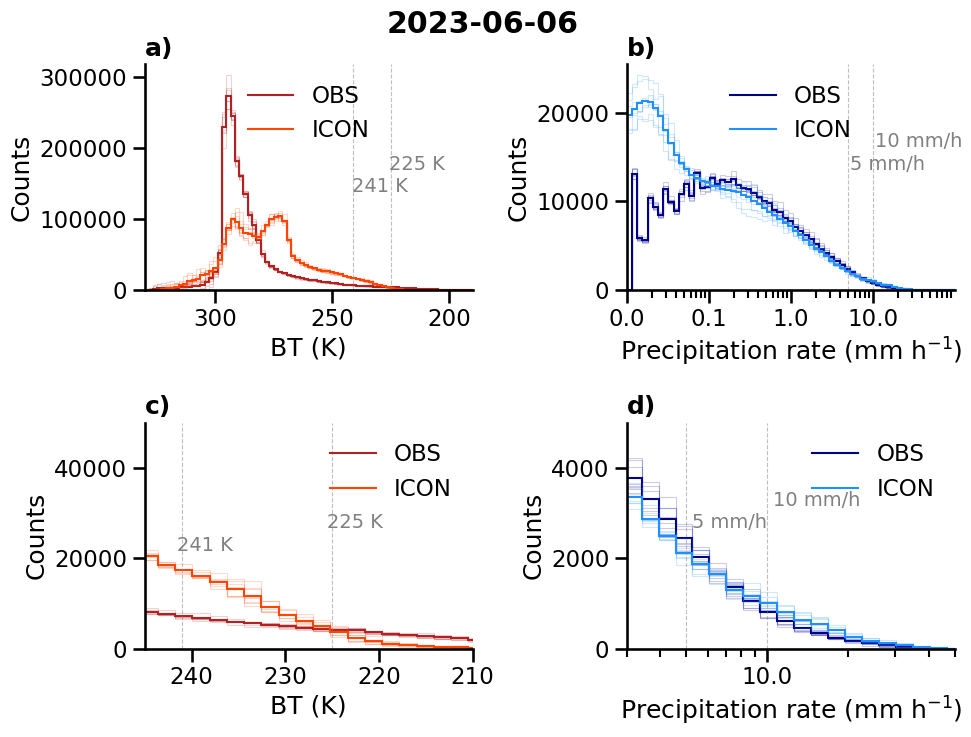

In [15]:
sns.set_context("talk")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

plot_pdf_pair( ax=axes[0,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=80, pad=1), colors=[color_tb_obs, color_tb_icon],
    labels=["OBS", "ICON"], xlabel="BT (K)", vlines=[(225, "225 K",0.6), (241, "241 K",0.5)], invert_x=True,
    xlim=(190,330), filter_positive=True,title = "a)")

plot_pdf_pair( ax=axes[0,1], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80),
    colors=[color_precip_obs, color_precip_icon], labels=["OBS", "ICON"], xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)],
    xscale="log", xlim=(1e-2, 1e2-0.1), filter_positive=True, title = "b)")

plot_pdf_pair( ax=axes[1,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=80, pad=1), colors=[color_tb_obs, color_tb_icon], labels=["OBS", "ICON"], xlabel="BT (K)", vlines=[(225, "225 K",0.6), (241, "241 K",0.5)], invert_x=True, xlim=(210,245),
    title = "c)", filter_positive=True,ylim = (0,50000))

plot_pdf_pair( ax=axes[1,1], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80), colors=[color_precip_obs, color_precip_icon], labels=["OBS", "ICON"],
    xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)], xscale="log", xlim=(3, 50),
    filter_positive=True, title = "d)", ylim= (0,5000))


fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()


plt.show()


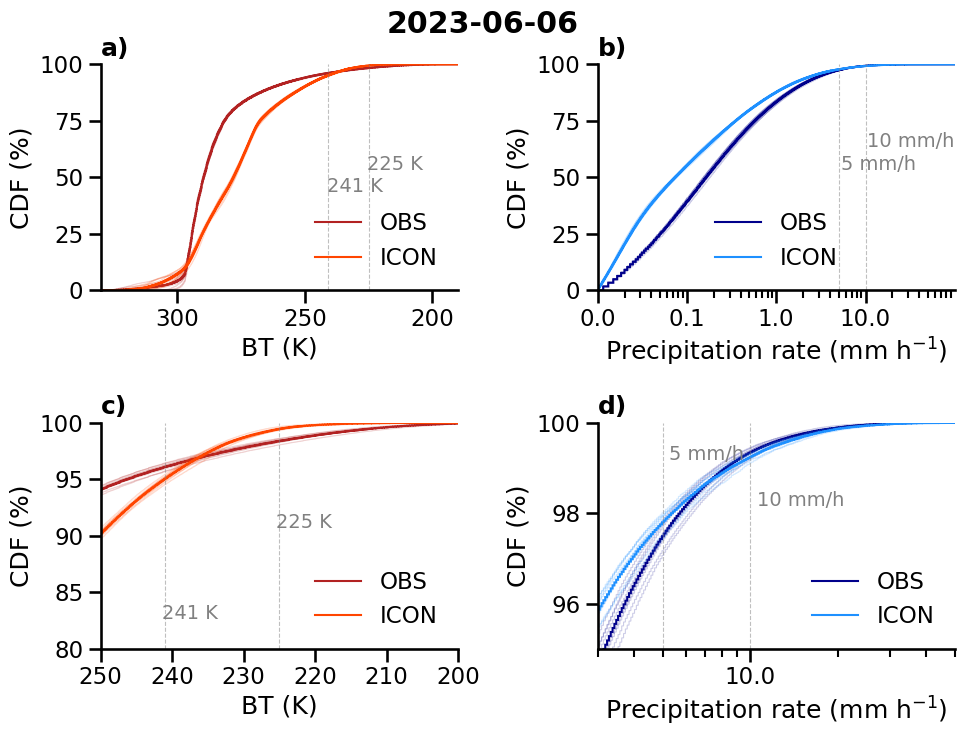

In [16]:
# ── plotting ─────────────────────────────────────────────────────────────────

sns.set_context("talk")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

plot_cdf_pair( ax=axes[0,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=800, pad=1), colors=[color_tb_obs, color_tb_icon], labels=["OBS", "ICON"], xlabel="BT (K)",
    vlines=[(225, "225 K",0.6), (241, "241 K",0.5)], invert_x=True, xlim=(190,330), filter_positive=True, invert_y = True,
    title = "a)")

plot_cdf_pair( ax=axes[0,1], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 800), colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)], xscale="log",
    xlim=(1e-2, 1e2-0.1), filter_positive=True, title = "b)")


plot_cdf_pair( ax=axes[1,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=800, pad=1), colors=[color_tb_obs, color_tb_icon],
    labels=["OBS", "ICON"], xlabel="BT (K)", vlines=[(225, "225 K",0.6), (241, "241 K",0.2)], invert_x=True, xlim=(200,250),
    invert_y = True, ylim= (0.8,1), filter_positive=True, title = "c)")

plot_cdf_pair( ax=axes[1,1], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 800), colors=[color_precip_obs, color_precip_icon], labels=["OBS", "ICON"],
    xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.9), (10, "10 mm/h",0.7)], xscale="log", xlim=(3, 50),
    filter_positive=True, ylim = (0.95,1), title = "d)")


fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()


plt.show()


# cdf show
- BT from ICON is too cold for lower BTS (below approx 230K) and too warm for colder BTs (above 230K)
- too little weak precip rates but too much strong precip rates (above approx 7)

## 2. Counts x bins

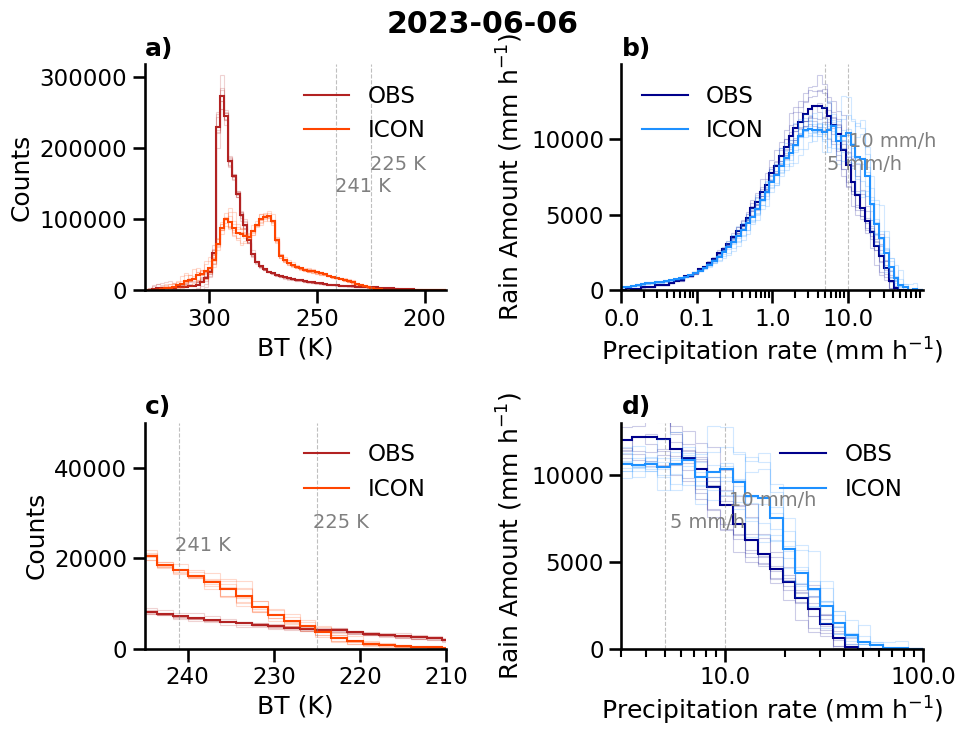

In [17]:

sns.set_context("talk")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

plot_pdf_pair( ax=axes[0,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=80, pad=1), colors=[color_tb_obs, color_tb_icon], labels=["OBS", "ICON"],
    xlabel="BT (K)", vlines=[(225, "225 K",0.6), (241, "241 K",0.5)], invert_x=True, xlim=(190,330),filter_positive=True,
    title = "a)")

plot_pdf_contri_pair( ax=axes[0,1], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80), colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)], xscale="log",
    xlim=(1e-2, 1e2-0.1), filter_positive=True, title = "b)" ,ylabel = "rain")

plot_pdf_pair( ax=axes[1,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=80, pad=1), colors=[color_tb_obs, color_tb_icon],
    labels=["OBS", "ICON"], xlabel="BT (K)", vlines=[(225, "225 K",0.6), (241, "241 K",0.5)], invert_x=True,
    xlim=(210,245), title = "c)", filter_positive=True,ylim = (0,50000))

plot_pdf_contri_pair( ax=axes[1,1],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 80),
    colors=[color_precip_obs, color_precip_icon],labels=["OBS", "ICON"],xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)],
                      xscale="log", xlim=(3, 100),filter_positive=True,title = "d)",ylim= (0,13000), ylabel = "rain")


fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()


plt.show()


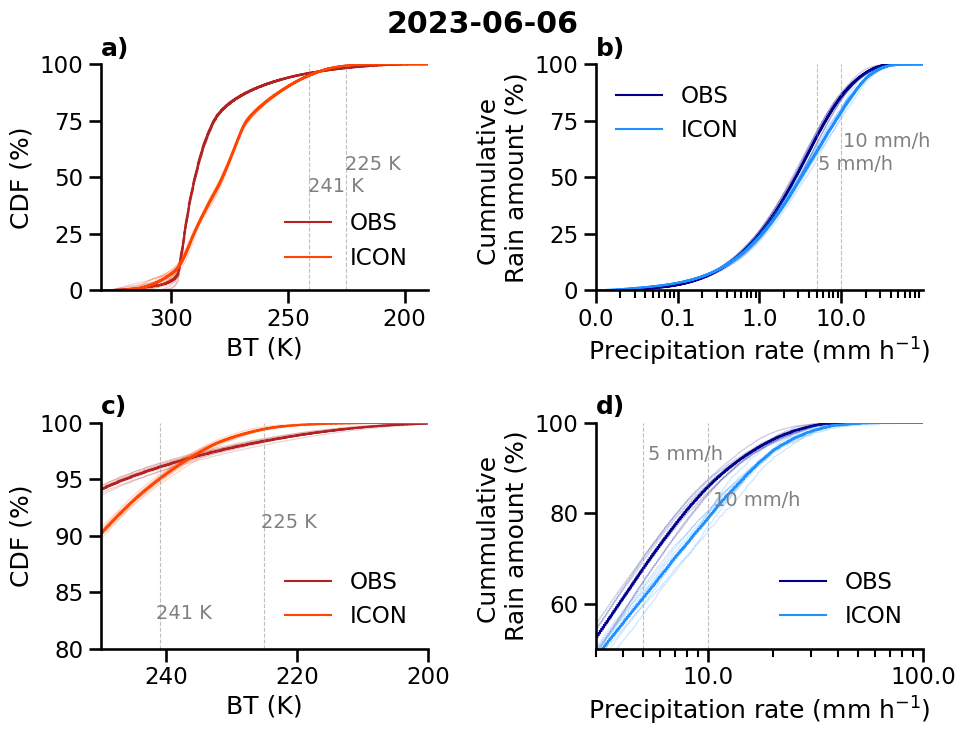

In [18]:
sns.set_context("talk")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

plot_cdf_pair(ax=axes[0,0],data_list=[tb_obs, tb_icon],bins=linear_bins(tb_icon, tb_obs, n=800, pad=1),colors=[color_tb_obs, color_tb_icon],
    labels=["OBS", "ICON"],xlabel="BT (K)",vlines=[(225, "225 K",0.6), (241, "241 K",0.5)],invert_x=True,xlim=(190,330),
    filter_positive=True,invert_y = True,title = "a)")

plot_cdf_contri_pair(ax=axes[0,1],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 800),colors=[color_precip_obs, color_precip_icon],labels=["OBS", "ICON"],
    xlabel="Precipitation rate (mm h$^{-1}$)",vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)],xscale="log",xlim=(1e-2, 1e2-0.1),
    filter_positive=True,title = "b)", ylabel = "rain")


plot_cdf_pair(ax=axes[1,0],data_list=[tb_obs, tb_icon],bins=linear_bins(tb_icon, tb_obs, n=800, pad=1),colors=[color_tb_obs, color_tb_icon],labels=["OBS", "ICON"],
    xlabel="BT (K)",vlines=[(225, "225 K",0.6), (241, "241 K",0.2)],invert_x=True,xlim=(200,250),invert_y = True,
    ylim= (0.8,1),filter_positive=True,title = "c)")

plot_cdf_contri_pair(ax=axes[1,1],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 800),colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"],xlabel="Precipitation rate (mm h$^{-1}$)",vlines=[(5, "5 mm/h",0.9), (10, "10 mm/h",0.7)],xscale="log",
    xlim=(3, 100),filter_positive=True,ylim = (0.5,1),title = "d)", ylabel = "rain")


fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()


plt.show()


## precip and TB getrennt

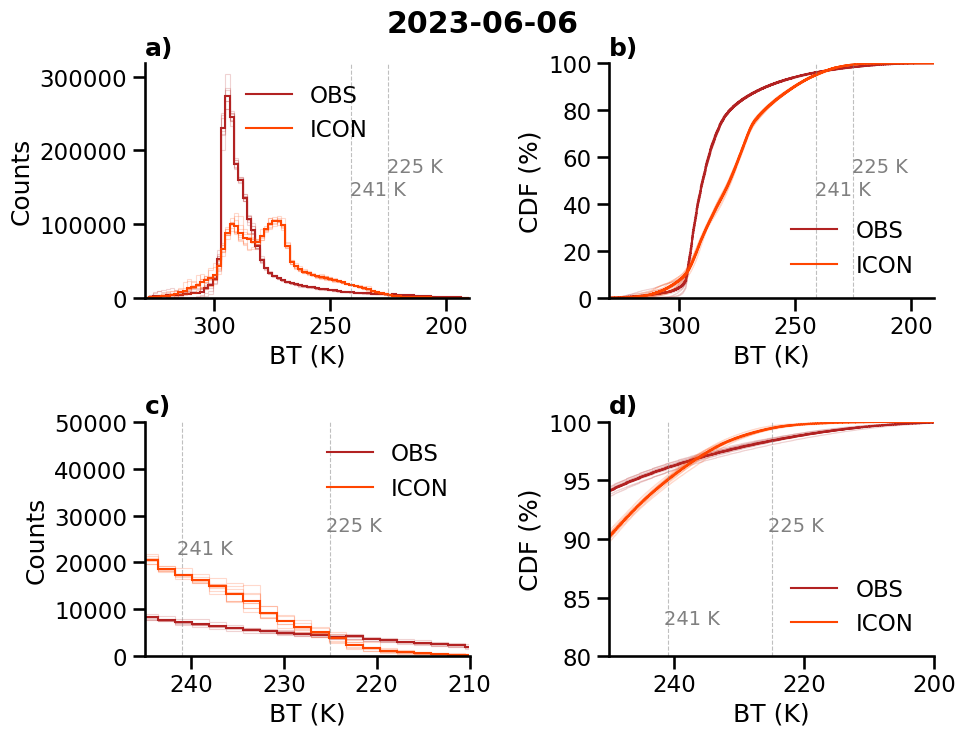

In [19]:

sns.set_context("talk")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

plot_pdf_pair( ax=axes[0,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=80, pad=1), colors=[color_tb_obs, color_tb_icon], labels=["OBS", "ICON"],
    xlabel="BT (K)", vlines=[(225, "225 K",0.6), (241, "241 K",0.5)], invert_x=True, xlim=(190,330),filter_positive=True,
    title = "a)")

plot_cdf_pair(ax=axes[0,1],data_list=[tb_obs, tb_icon],bins=linear_bins(tb_icon, tb_obs, n=800, pad=1),colors=[color_tb_obs, color_tb_icon],
    labels=["OBS", "ICON"],xlabel="BT (K)",vlines=[(225, "225 K",0.6), (241, "241 K",0.5)],invert_x=True,xlim=(190,330),
    filter_positive=True,invert_y = True,title = "b)")


plot_pdf_pair( ax=axes[1,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=80, pad=1), colors=[color_tb_obs, color_tb_icon],
    labels=["OBS", "ICON"], xlabel="BT (K)", vlines=[(225, "225 K",0.6), (241, "241 K",0.5)], invert_x=True,
    xlim=(210,245), title = "c)",filter_positive=True, ylim = (0,50000))

plot_cdf_pair(ax=axes[1,1],data_list=[tb_obs, tb_icon],bins=linear_bins(tb_icon, tb_obs, n=800, pad=1),colors=[color_tb_obs, color_tb_icon],labels=["OBS", "ICON"],
    xlabel="BT (K)",vlines=[(225, "225 K",0.6), (241, "241 K",0.2)],invert_x=True,xlim=(200,250),invert_y = True,
    ylim= (0.8,1),filter_positive=True,title = "d)")

fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()

fig.savefig(os.path.join(outputdir,f"cdf_BT_{day}.pdf"), bbox_inches="tight")
plt.show()


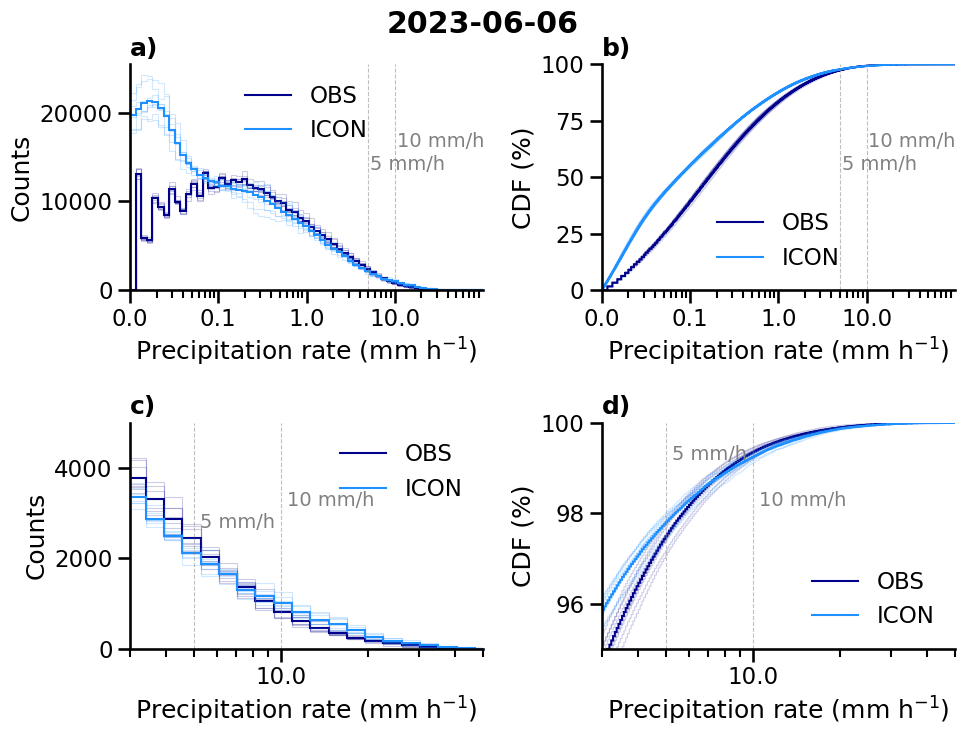

In [20]:
# ── plotting ─────────────────────────────────────────────────────────────────

sns.set_context("talk")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

plot_pdf_pair( ax=axes[0,0], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80),
    colors=[color_precip_obs, color_precip_icon], labels=["OBS", "ICON"], xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)],
    xscale="log", xlim=(1e-2, 1e2-0.1), filter_positive=True, title = "a)")

plot_cdf_pair( ax=axes[0,1], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 800), colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)], xscale="log",
    xlim=(1e-2, 1e2-0.1), filter_positive=True, title = "b)")

plot_pdf_pair( ax=axes[1,0], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80), colors=[color_precip_obs, color_precip_icon], labels=["OBS", "ICON"],
    xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)], xscale="log", xlim=(3, 50),
    filter_positive=True, title = "c)", ylim= (0,5000))



plot_cdf_pair( ax=axes[1,1], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 800), colors=[color_precip_obs, color_precip_icon], labels=["OBS", "ICON"],
    xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.9), (10, "10 mm/h",0.7)], xscale="log", xlim=(3, 50),
    filter_positive=True, ylim = (0.95,1), title = "d)")


fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()


plt.show()


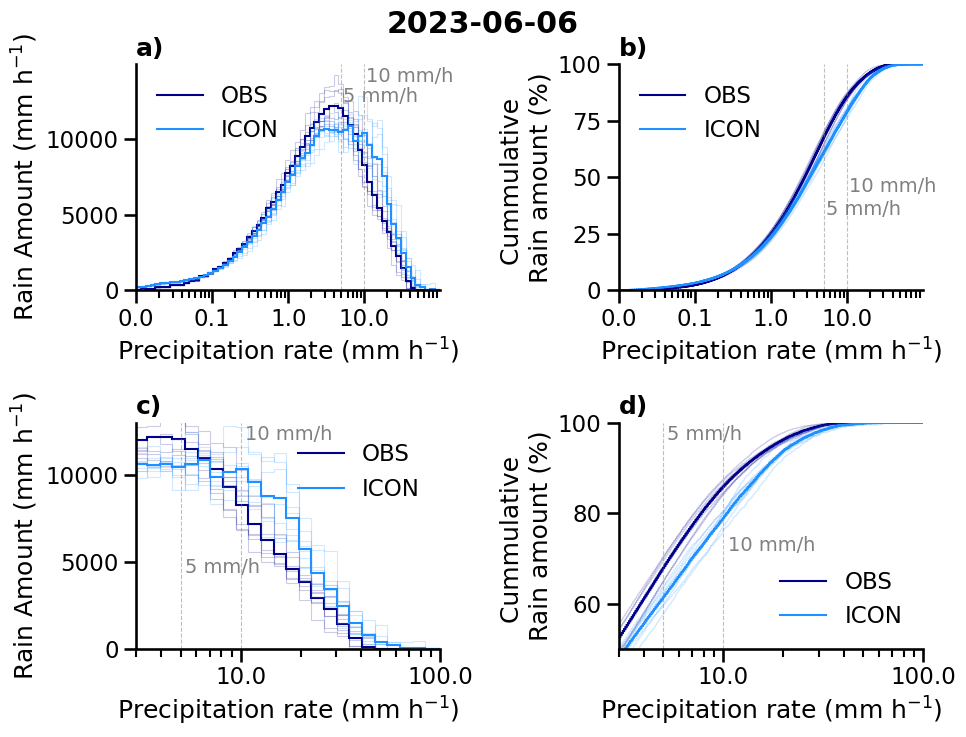

In [21]:
sns.set_context("talk")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

plot_pdf_contri_pair( ax=axes[0,0], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80), colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.9), (10, "10 mm/h",0.99)], xscale="log",
    xlim=(1e-2, 1e2-0.1), filter_positive=True, title = "a)", ylabel = "rain")

plot_cdf_contri_pair(ax=axes[0,1],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 800),colors=[color_precip_obs, color_precip_icon],labels=["OBS", "ICON"],
    xlabel="Precipitation rate (mm h$^{-1}$)",vlines=[(5, "5 mm/h",0.4), (10, "10 mm/h",0.5)],xscale="log",xlim=(1e-2, 1e2-0.1),
    filter_positive=True,title = "b)", ylabel = "rain")

plot_pdf_contri_pair( ax=axes[1,0],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 80),
    colors=[color_precip_obs, color_precip_icon],labels=["OBS", "ICON"],xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.4), (10, "10 mm/h",0.99)],
                      xscale="log", xlim=(3, 100),filter_positive=True,title = "c)",ylim= (0,13000), ylabel = "rain")


plot_cdf_contri_pair(ax=axes[1,1],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 800),colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"],xlabel="Precipitation rate (mm h$^{-1}$)",vlines=[(5, "5 mm/h",0.99), (10, "10 mm/h",0.5)],xscale="log",
    xlim=(3, 100),filter_positive=True,ylim = (0.5,1),title = "d)", ylabel = "rain")



fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()


plt.show()


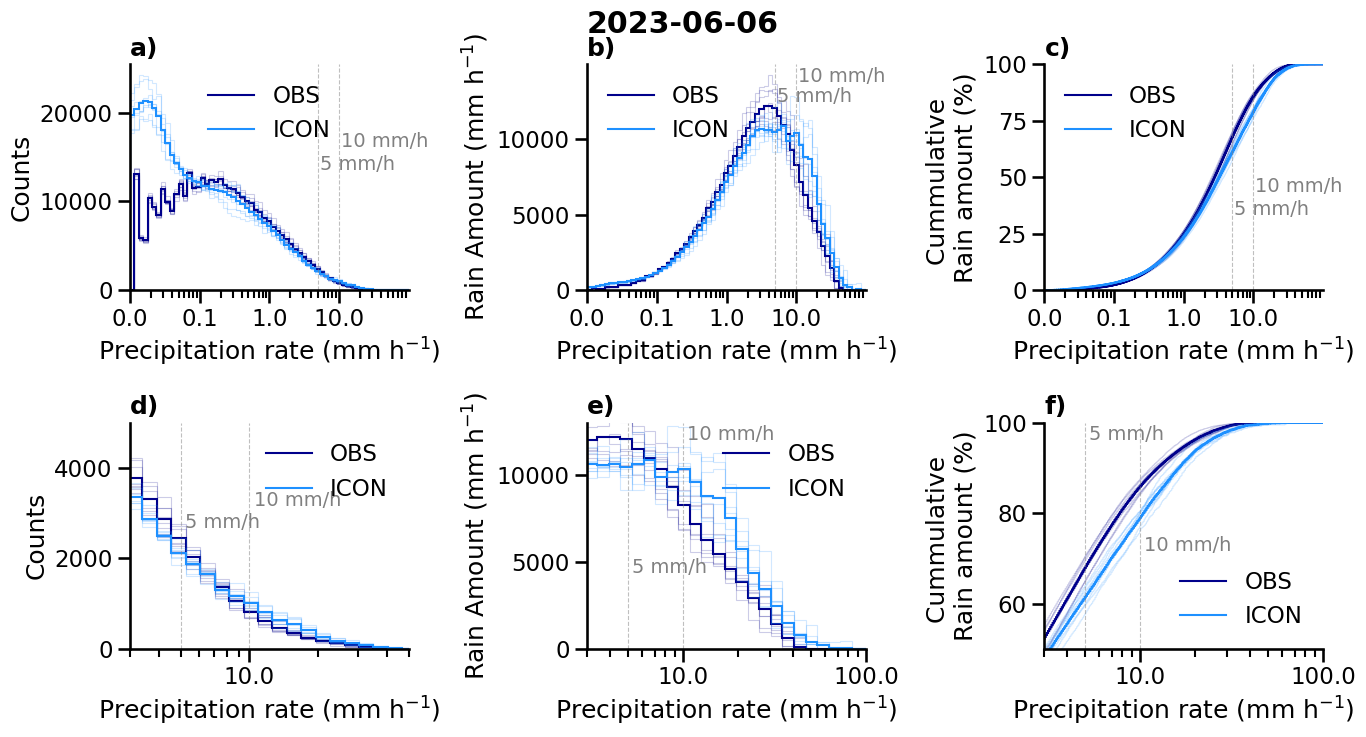

In [22]:
# ── plotting ─────────────────────────────────────────────────────────────────

sns.set_context("talk")
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# precip pdf
plot_pdf_pair( ax=axes[0,0], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80),
    colors=[color_precip_obs, color_precip_icon], labels=["OBS", "ICON"], xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)],
    xscale="log", xlim=(1e-2, 1e2-0.1), filter_positive=True, title = "a)")

# precip pdf contri
plot_pdf_contri_pair( ax=axes[0,1], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80), colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.9), (10, "10 mm/h",0.99)], xscale="log",
    xlim=(1e-2, 1e2-0.1), filter_positive=True, title = "b)", ylabel = "rain")

# precip cdf contri
plot_cdf_contri_pair(ax=axes[0,2],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 800),colors=[color_precip_obs, color_precip_icon],labels=["OBS", "ICON"],
    xlabel="Precipitation rate (mm h$^{-1}$)",vlines=[(5, "5 mm/h",0.4), (10, "10 mm/h",0.5)],xscale="log",xlim=(1e-2, 1e2-0.1),
    filter_positive=True,title = "c)", ylabel = "rain")



# zoom precip pdf
plot_pdf_pair( ax=axes[1,0], data_list=[precip_obs, precip_icon], bins=log_bins(-2, 3, 80), colors=[color_precip_obs, color_precip_icon], labels=["OBS", "ICON"],
    xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.6), (10, "10 mm/h",0.7)], xscale="log", xlim=(3, 50),
    filter_positive=True, title = "d)", ylim= (0,5000))


# zoom precip pdf contri
plot_pdf_contri_pair( ax=axes[1,1],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 80),
    colors=[color_precip_obs, color_precip_icon],labels=["OBS", "ICON"],xlabel="Precipitation rate (mm h$^{-1}$)", vlines=[(5, "5 mm/h",0.4), (10, "10 mm/h",0.99)],
                      xscale="log", xlim=(3, 100),filter_positive=True,title = "e)",ylim= (0,13000), ylabel = "rain")

# zoom precip cdf contri
plot_cdf_contri_pair(ax=axes[1,2],data_list=[precip_obs, precip_icon],bins=log_bins(-2, 3, 800),colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"],xlabel="Precipitation rate (mm h$^{-1}$)",vlines=[(5, "5 mm/h",0.99), (10, "10 mm/h",0.5)],xscale="log",
    xlim=(3, 100),filter_positive=True,ylim = (0.5,1),title = "f)", ylabel = "rain")



fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()

fig.savefig(os.path.join(outputdir,f"cdf_precip_{day}.pdf"),bbox_inches="tight")
plt.show()


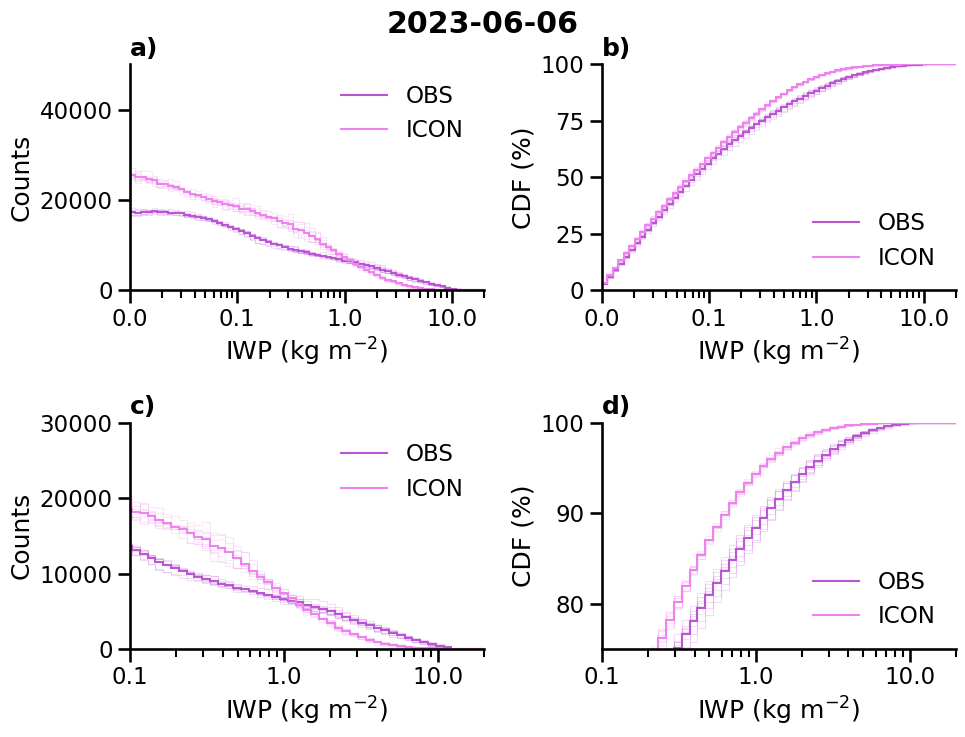

In [23]:

sns.set_context("talk")
fig, axes = plt.subplots(2,2, figsize=(10, 8))

# iwp pdf
plot_pdf_pair( ax=axes[0,0], data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-2, high=2, n = 80) ,colors=[color_iwp_obs, color_iwp_icon], labels=["OBS", "ICON"],
    xlabel="IWP (kg m$^{-2}$)", xscale = "log", xlim = (1e-2, 20),filter_positive=True,ylim=(0, 50000),
    title = "a)")
# iwp cdf
plot_cdf_pair(ax=axes[0,1],data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-2, high=2, n = 80),colors=[color_iwp_obs, color_iwp_icon],
    labels=["OBS", "ICON"],xlabel="IWP (kg m$^{-2}$)",xscale = "log",xlim= (1e-2, 20),filter_positive=True,title = "b)")



# iwp pdf zoom
plot_pdf_pair( ax=axes[1,0], data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-2, high=2, n = 80) ,colors=[color_iwp_obs, color_iwp_icon], labels=["OBS", "ICON"],
    xlabel="IWP (kg m$^{-2}$)", xscale = "log", xlim = (0.1, 20),filter_positive=True,ylim=(0, 30000),
    title = "c)")

# iwp cdf zoom
plot_cdf_pair(ax=axes[1,1],data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-2, high=2, n = 80),colors=[color_iwp_obs, color_iwp_icon],
    labels=["OBS", "ICON"],xlabel="IWP (kg m$^{-2}$)",xscale = "log",xlim= (0.1, 20),filter_positive=True,title = "d)",ylim = (0.75,1) )



fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()

plt.show()


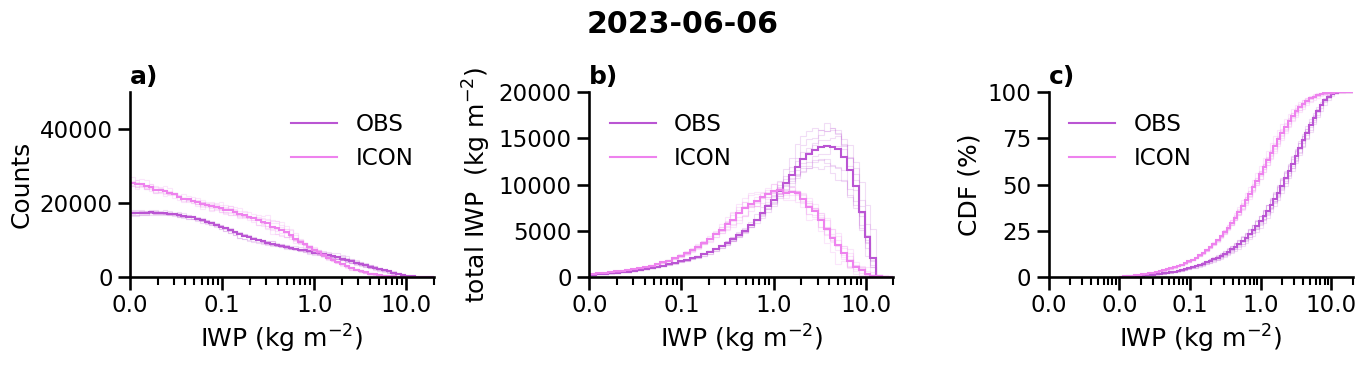

In [24]:

sns.set_context("talk")
fig, axes = plt.subplots(1,3, figsize=(14, 4))

# iwp pdf
plot_pdf_pair( ax=axes[0], data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-2, high=2, n = 80) ,colors=[color_iwp_obs, color_iwp_icon], labels=["OBS", "ICON"],
    xlabel="IWP (kg m$^{-2}$)", xscale = "log", xlim = (1e-2, 20),filter_positive=True,ylim=(0, 50000),
    title = "a)")

plot_pdf_contri_pair( ax=axes[1], data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-3, high=2, n = 80) ,colors=[color_iwp_obs, color_iwp_icon], labels=["OBS", "ICON"],
    xlabel="IWP (kg m$^{-2}$)", xscale = "log", xlim = (1e-2, 20),filter_positive=True,ylim=(0, 20000),
    title = "b)", ylabel = "total IWP  (kg m$^{-2}$)")

# iwp cdf
plot_cdf_contri_pair(ax=axes[2],data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-2, high=2, n = 80),colors=[color_iwp_obs, color_iwp_icon],
    labels=["OBS", "ICON"],xlabel="IWP (kg m$^{-2}$)",xscale = "log",xlim= (1e-3, 20),filter_positive=True,title = "c)")



# # iwp pdf zoom
# plot_pdf_pair( ax=axes[1,0], data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-2, high=2, n = 80) ,colors=[color_iwp_obs, color_iwp_icon], labels=["OBS", "ICON"],
#     xlabel="IWP (kg m$^{-2}$)", xscale = "log", xlim = (0.1, 20),filter_positive=True,ylim=(0, 30000),
#     title = "d)")



# # iwp cdf
# plot_cdf_contri_pair(ax=axes[1,2],data_list=[iwp_obs, iwp_icon],bins=log_bins(low=-2, high=2, n = 80),colors=[color_iwp_obs, color_iwp_icon],
#     labels=["OBS", "ICON"],xlabel="IWP (kg m$^{-2}$)",xscale = "log",xlim= (1, 20),filter_positive=True,title = "c)")

fig.suptitle(f"{day}", fontweight="bold", y=0.93)
plt.tight_layout()

fig.savefig(os.path.join(outputdir,f"cdf_iwp_{day}.pdf"),bbox_inches="tight")

plt.show()


In [25]:
# old stuff bck

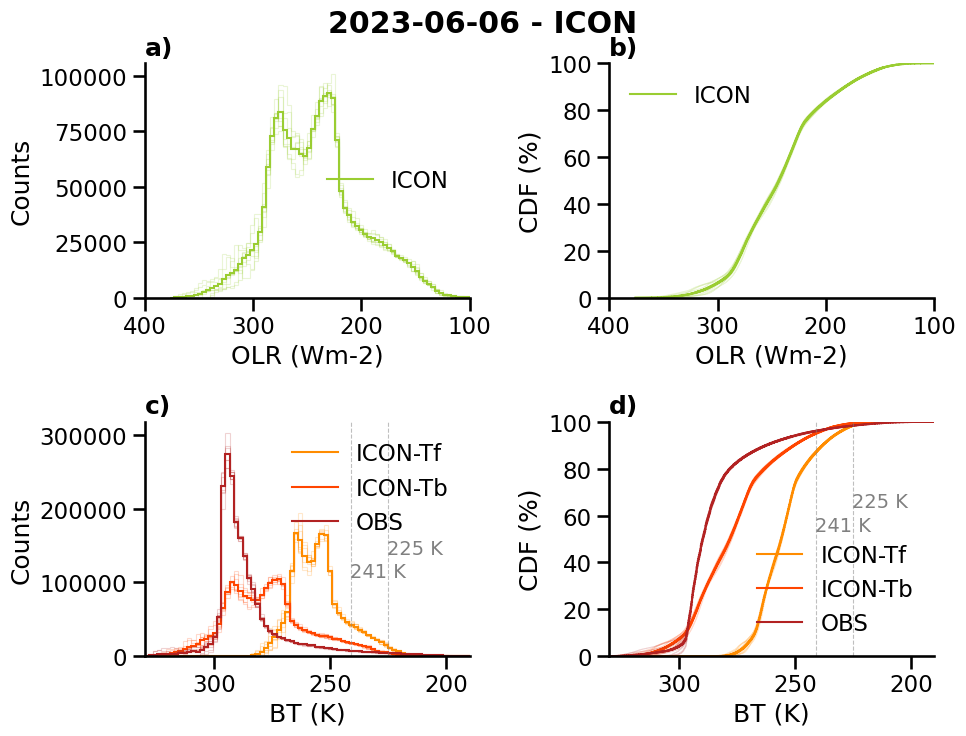

In [26]:

sns.set_context("talk")
fig, axes = plt.subplots(2,2, figsize=(10, 8))



plot_pdf_pair( ax=axes[0,0], data_list=[rlut_icon], bins=linear_bins(rlut_icon, n=80, pad=1), colors=[color_rlut_icon], labels=["ICON"],
    xlabel="OLR (Wm-2)", invert_x=True, xlim=(100,400),filter_positive=True,
    title = "a)")

plot_cdf_pair(ax=axes[0,1],data_list=[rlut_icon],bins=linear_bins(rlut_icon, n=800, pad=1),colors=[color_rlut_icon],
    labels=["ICON"],xlabel="OLR (Wm-2)",invert_x=True,xlim=(100,400),
    filter_positive=True,invert_y = True,title = "b)")


plot_pdf_pair( ax=axes[1,0], data_list=[tf_icon,tb_icon,tb_obs], bins=linear_bins(tf_icon,tb_icon,tb_obs, n=80, pad=1), colors=[color_tf_icon,color_tb_icon, color_tb_obs], labels=["ICON-Tf","ICON-Tb","OBS"],
    xlabel="BT (K)", vlines=[(225, "225 K",0.5), (241, "241 K",0.4)], invert_x=True, xlim=(190,330),filter_positive=True,
    title = "c)")

plot_cdf_pair(ax=axes[1,1],data_list=[tf_icon,tb_icon,tb_obs],bins=linear_bins(tf_icon,tb_icon,tb_obs, n=800, pad=1),colors=[color_tf_icon,color_tb_icon,color_tb_obs],
    labels=["ICON-Tf","ICON-Tb","OBS"],xlabel="BT (K)", vlines=[(225, "225 K",0.7), (241, "241 K",0.6)],invert_x=True,xlim=(190,330),
    filter_positive=True,invert_y = True,title = "d)")

# plot_pdf_pair( ax=axes[2,0], data_list=[tb_obs, tb_icon], bins=linear_bins(tb_icon, tb_obs, n=80, pad=1), colors=[color_tb_obs, color_tb_icon], labels=["OBS", "ICON"],
#     xlabel="BT (K)", vlines=[(225, "225 K",0.6), (241, "241 K",0.5)], invert_x=True, xlim=(190,330),filter_positive=True,
#     title = "e)")

# plot_cdf_pair(ax=axes[2,1],data_list=[tb_obs, tb_icon],bins=linear_bins(tb_icon, tb_obs, n=800, pad=1),colors=[color_tb_obs, color_tb_icon],
#     labels=["OBS", "ICON"],xlabel="BT (K)",vlines=[(225, "225 K",0.6), (241, "241 K",0.5)],invert_x=True,xlim=(190,330),
#     filter_positive=True,invert_y = True,title = "f)")




fig.suptitle(f"{day} - ICON", fontweight="bold", y=0.93)
plt.tight_layout()

fig.savefig(os.path.join(outputdir,f"cdf_icon_bts_{day}.pdf"), bbox_inches="tight")
plt.show()


# Histograms